# Computing the forward model

`
Authors: Marijn van Vliet, Britta Westner, Eric Larson, Denis Engemann, Alex Gramfort
`

License: BSD (3-clause)

In [1]:
# This makes figures appear inside the notebook instead of in a new window.
%matplotlib inline

# We set the log-level of MNE-Python to 'warning' so the output is less verbose:
import mne
mne.set_log_level('error')

# Disable all warnings so they don't end up in the HTML.
import warnings
warnings.filterwarnings("ignore")

# Specify rendering backends
mne.viz.set_browser_backend("qt")

## Setup

Mostly the same as before, but we are now also setting up FreeSurfer.

In [2]:
# These are the Python packages we will use in this session.
import numpy as np  # for numerical computations
import matplotlib.pyplot as plt  # for making custom figures
import mne  # for MEG and EEG data analysis

# Change the following path to where you extracted mne_course_data.zip
data_path = "./data"

# Based on the `data_path` you specified above, this is where the raw MEG+EEG data should be.
raw_fname = f"{data_path}/sub-01/sub-01_ses-meg_task-facerecognition_run-01_meg.fif"

# Change the following path to where you want to save the processed data.
processed_path = "./data/processed"

# NEW: This is the FreeSurfer "subjects" folder, where the program expects the MRI data to be
subjects_dir = f"{data_path}/freesurfer"

To compute a forward operator (also known as forward model, gain matrix, or -less accurately- lead field) we need:
- the BEM surfaces
- a ``-trans.fif`` file that contains the coregistration information
- a source space
 
In this session we'll set all three of these up.

### Visualize and compute the BEM model

Normally, one would use the [FreeSurfer](https://surfer.nmr.mgh.harvard.edu/fswiki/DownloadAndInstall#Download) program on the MRI data to create 3D meshes of the various tissue boundaries. This program does not easily run on Windows and takes hours to complete, hence the resulting files are already present in your `data/freesurfer` folder, which we will call the `subjects_dir` in MNE-Python.

```{note}
If you would like to try out BEM reconstruction for yourself later, you can install FreeSurfer on MacOS or Linux directly and in a VirtualMachine for Windows. 

    mne watershed_bem -s sub-01 -d data/freesurfer --overwrite
    mne make_scalp_surfaces -s sub-01 -d data/freesurfer --force --overwrite
```

We can have a look at the MRI using the [`nilearn`](https://nilearn.github.io/stable/index.html) package:

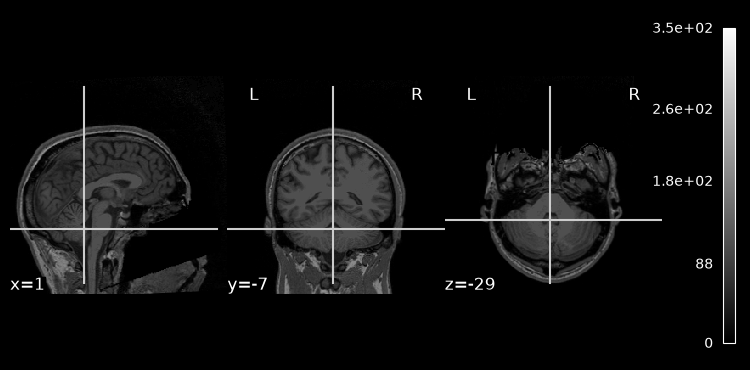

In [3]:
from nilearn import plotting
plotting.plot_anat(f"{subjects_dir}/sub-01/mri/T1.mgz");
plt.show()

And let's look at the BEM surfaces that FreeSurfer extracted for us:

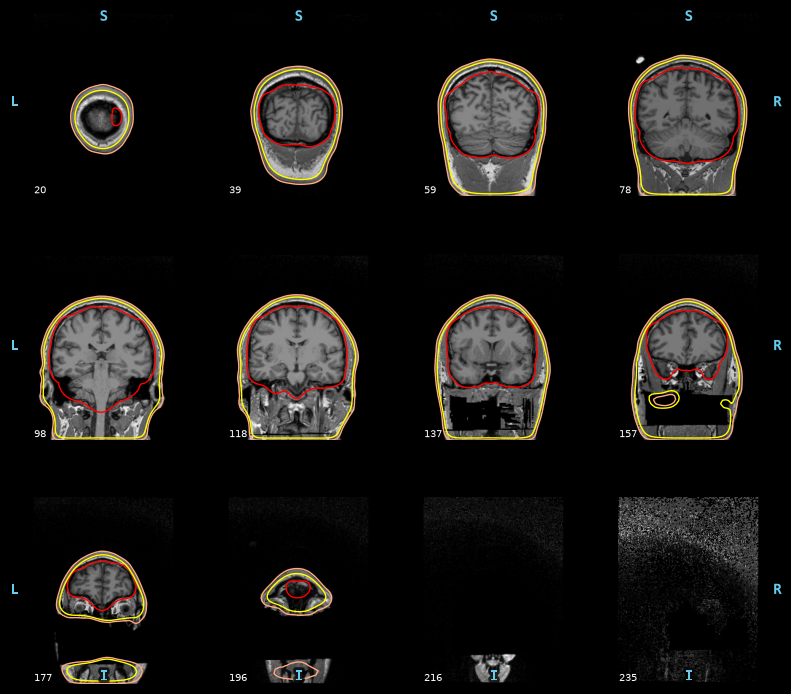

In [4]:
mne.viz.plot_bem(subject="sub-01", subjects_dir=subjects_dir);

Interesting artifacts at the front of the head... this is because the MRI has been anonymized: the face area has been removed!

From the BEM surfaces, we can create the actual mathematical BEM model that simulates how current and magnetic fields propagate through the head. MNE-Python calls this the BEM "solution".

In [5]:
# conductivity = (0.3,)  # for single layer
conductivity = (0.3, 0.006, 0.3)  # for three layers
model = mne.make_bem_model(ico=4, conductivity=conductivity,
                           subject="sub-01", subjects_dir=subjects_dir)
bem_sol = mne.make_bem_solution(model)
mne.write_bem_solution(f"{processed_path}/sub-01/sub-01-bem-sol.fif", bem_sol, overwrite=True)

## Coregistration 

The next step to a full head model is to bring in the locations of the EEG and MEG sensors. However, since the MRI and and MEG scanners are separate entities that don't talk to each other, we have to "manually" line up the BEM surfaces with the sensor locations. We call this process "co-registration" and MNE-Python provides a GUI for it. See [this video tutorial](https://youtu.be/ALV5qqMHLlQ).

### Visualizing the coregistration
Now that the coregistration is done, we just visually check the alignment with the following code.

In [6]:
trans_fname = f"{subjects_dir}/sub-01/sub-01-trans.fif"  # set this to where you saved the transformation
info = mne.io.read_info(raw_fname)
fig = mne.viz.plot_alignment(info, trans_fname, subject='sub-01', dig=True,
                             subjects_dir=subjects_dir, verbose=True);

Using pyvistaqt 3d backend.
Using outer_skin.surf for head surface.
Getting helmet for system 306m
Channel types::	grad: 204, mag: 102, eeg: 74


## Compute Source Space

The source space defines the positions of the candidate source locations. The following code computes such a source space with an OCT-6 resolution. 

Note that this is a surface (not volume) source space.

In [7]:
src = mne.setup_source_space(subject="sub-01", spacing="oct6", subjects_dir=subjects_dir,
                             add_dist=False)  # add_dist=True takes a lot of time
print(src)

<SourceSpaces: [<surface (lh), n_vertices=138517, n_used=4098>, <surface (rh), n_vertices=140607, n_used=4098>] MRI (surface RAS) coords, subject 'sub-01', ~21.5 MiB>


`src` contains two parts, one for the left hemisphere (4098 locations) and one for the right hemisphere (4098 locations).

We can visualize the source space together with the head model and also together with the MEG helmet.

In [8]:
mne.viz.plot_alignment(info, trans_fname, subject="sub-01",
                       src=src, subjects_dir=subjects_dir, dig=True,
                       surfaces=['head-dense', 'white'], coord_frame='meg')

### Compute forward solution

Now we have all the ingredients to compute the forward solution using [`mne.make_forward_solution()`](https://mne.tools/stable/generated/mne.make_forward_solution.html).

In [9]:
fwd = mne.make_forward_solution(
    raw_fname,
    trans=trans_fname,
    src=src,
    bem=bem_sol,
    meg=True,  # include MEG channels
    eeg=True,  # exclude EEG channels
    mindist=5.0,  # ignore sources <= 5mm from inner skull
    n_jobs=-1)  # number of jobs to run in parallel
print(fwd)

<Forward | MEG channels: 306 | EEG channels: 74 | Source space: Surface with 8193 vertices | Source orientation: Free>


Here is the actual source -> sensor "leadfield" matrix:

In [10]:
leadfield = fwd["sol"]["data"]
n_sensors, n_dipoles = leadfield.shape
print(f"Leadfield size : {n_sensors} sensors x {n_dipoles} dipoles")

Leadfield size : 380 sensors x 24579 dipoles


We also save the forward model for later use:

In [11]:
mne.write_forward_solution(f"{processed_path}/sub-01/sub-01-fwd.fif", fwd, overwrite=True)

## Compute and show sensitivy maps

Let's compute a sensitivity map for gradiometers, we asked for the dipole orientation to be fixed.

In [12]:
sens_map = mne.sensitivity_map(fwd, ch_type="grad", mode="fixed")

Let's view in 3D:

In [13]:
# Set the color limits of this plot to something more useful than the default.
clim = dict(kind="value", lims=(0.0, 0.1, 1), smoothing_steps=3)

# Plot the sensitivity map on the white matter surface of the brain.
brain = sens_map.plot(subject="sub-01", subjects_dir=subjects_dir, time_label="GRAD sensitivity",
                      clim=clim, smoothing_steps=8, surface="white", hemi="both");

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Compute and plot the sensitivity mapss for gradiometers, magnetometers, and EEG, compare them. </li>
      <li>Which sensor type is the least sensitive to deep sources and which sensor type the most?</li>
      <li>Can you justify the claims that MEG is not sensitive to radial sources but EEG is?</li>     
      <li>Try changing the <code>mode</code> parameter in <code>mne.sensitivity_map</code> and see how fixed or free orientation forward operator change the pictures.</li>
    </ul>
</div>